<a href="https://colab.research.google.com/github/elfiel-code/cuadernos-de-machine-learning-y-deep-learning/blob/main/cuadernos/6_UNet_paso_a_paso.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

Ábrelo en Colab para verlo con fondo negro: en Colab, **Herramientas → Configuración → Sitio → Tema: oscuro**. Para correrlo, copia antes `topa_pasos.py` y tus datos a tu Google Drive (lee el README).

# <font color="greenyellow" size="7"><b>U-NET</b></font>

<font color="greenyellow" size="5"><b>Detección de <i>Ochroma pyramidale</i> · cuaderno paso a paso</b></font>

Este cuaderno entrena la **U-Net** de la tesis, paso a paso, con la misma receta de tu cuaderno Ultima_prueba_U-NET (CELDA 1 y 2 RGB): teselas de 640 px con su máscara de topa, corte 70/30 y 150 épocas con ResNet34 de ImageNet. Necesita GPU.

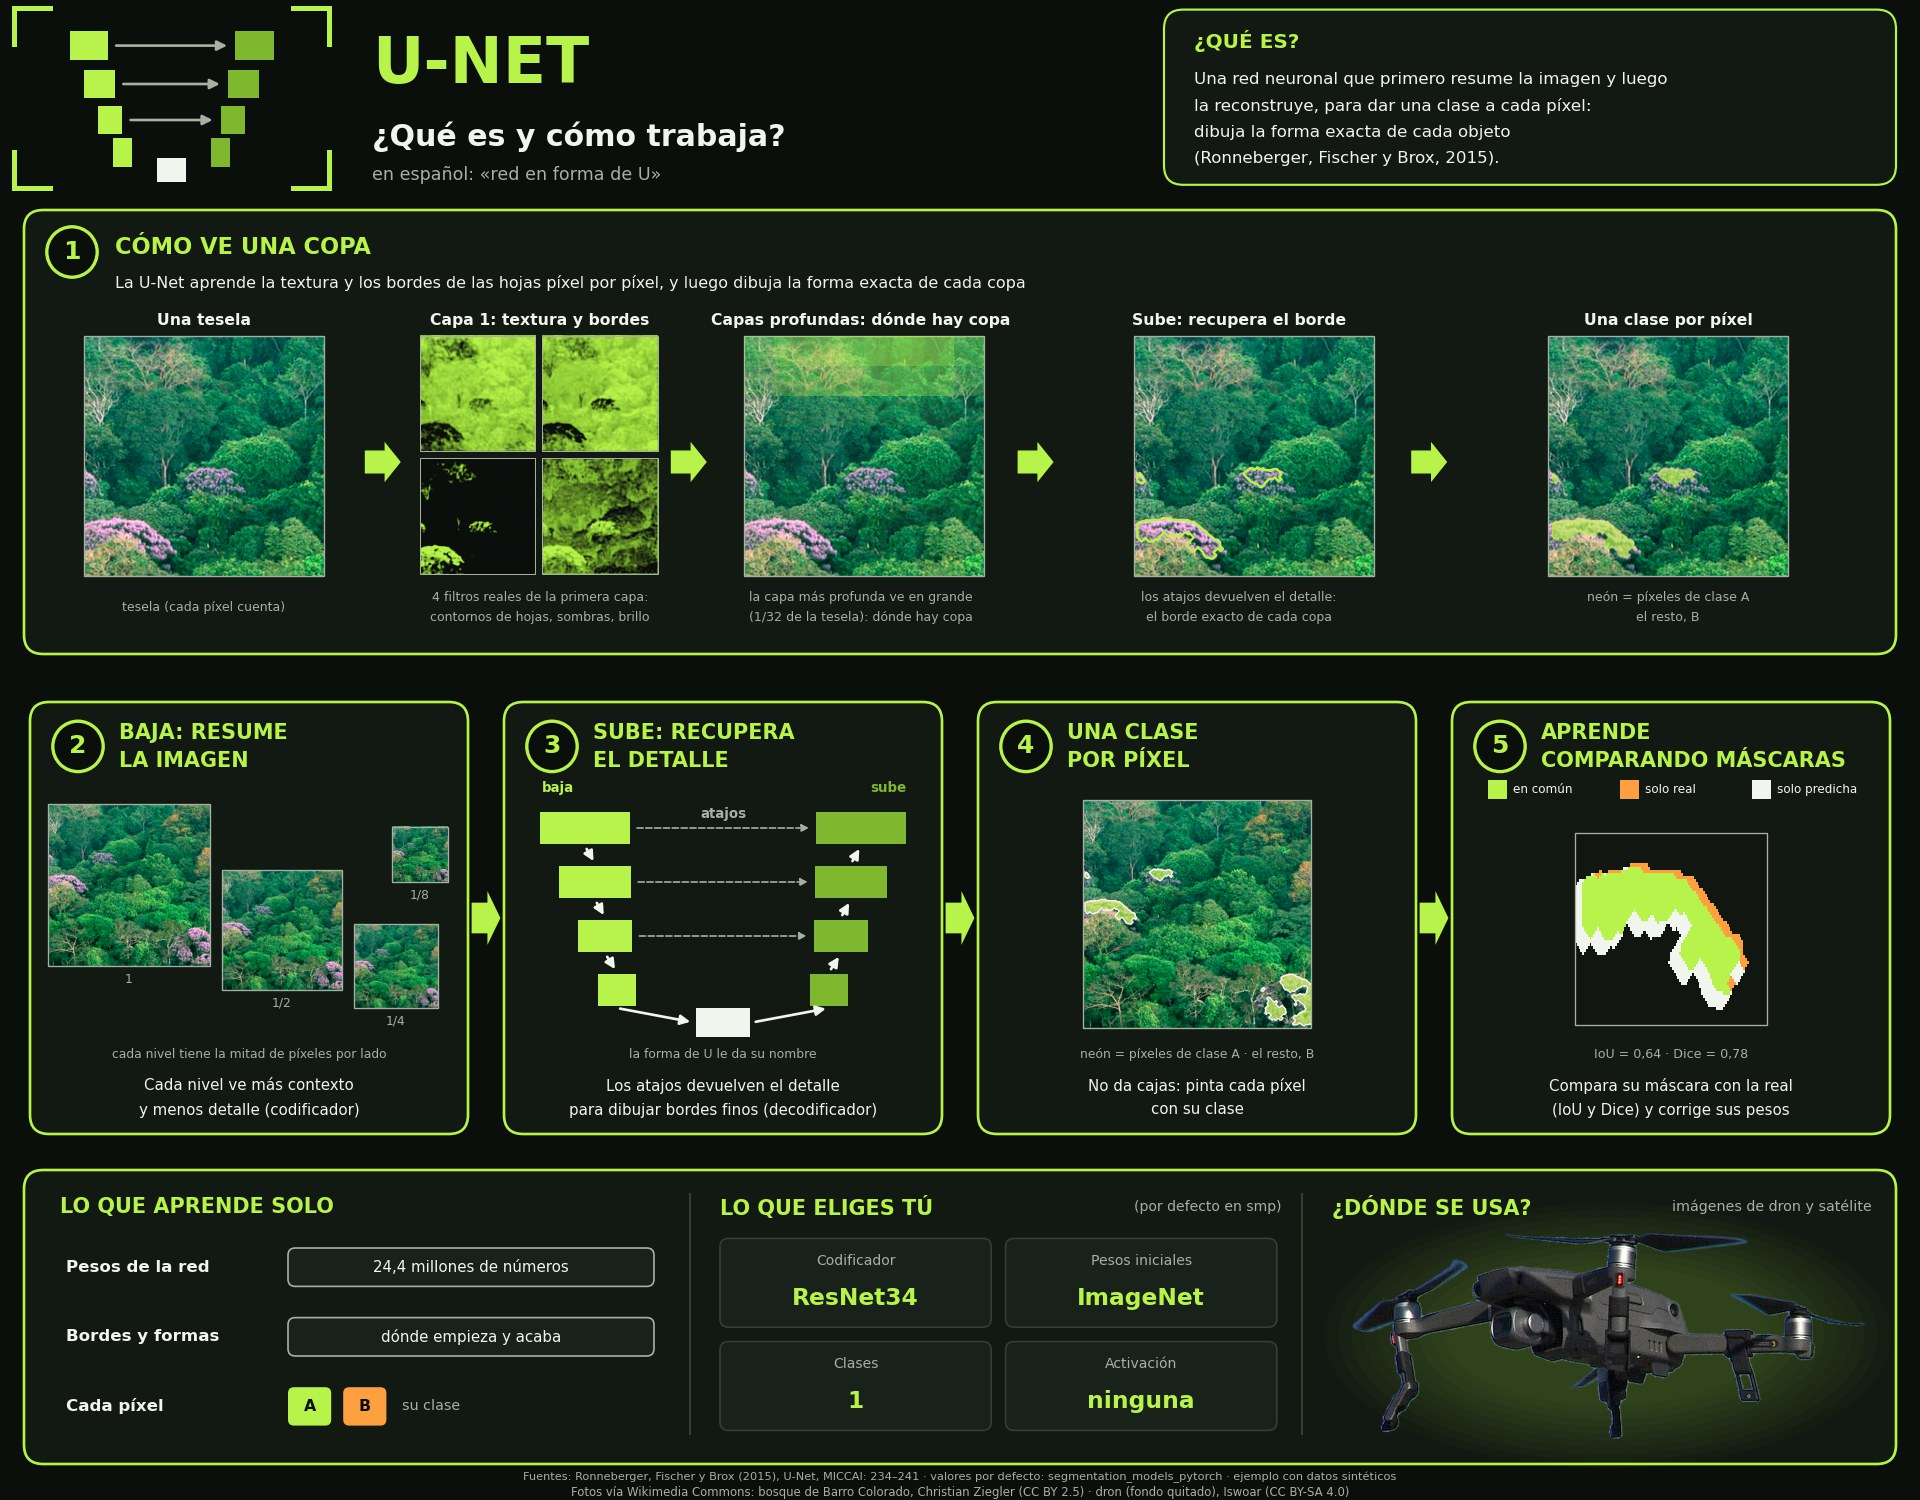

**Pasos:** **1** Conectar Drive y cargar las herramientas · **2** Rutas y parámetros · **3** Abrir el ortomosaico y ver tus polígonos · **4** Teselas de 640 px con su máscara y división 70/30 · **5** Solo si Colab se reinició: recuperar las teselas · **6** Entrenar la U-Net · **7** Examen por píxel en el 30 % · **8** Detectar en todo el ortomosaico · **9** Mapa final (tú eliges el estilo) · **10** Ortomosaico interactivo con barra de umbral · **11** Guardar las copas del umbral que elegiste

**Cómo usarlo:** corre las celdas en orden con ▶. Solo se cambia el **Paso 2** (rutas y parámetros); el resto ya está listo.

## <font color="greenyellow" size="6"><b>PASO 1 · Conectar Drive y cargar las herramientas</b></font>
**Para qué:** que Colab lea tus datos, instalar lo que necesita esta red y cargar las funciones de cada paso (`topa_pasos.py`).  
**Qué verás:** «Mounted at /content/drive». Antes de empezar: Entorno de ejecución → Cambiar tipo → GPU.

In [3]:
from google.colab import drive; drive.mount("/content/drive")
!pip install -q rasterio segmentation-models-pytorch
import sys; sys.path.append("/content/drive/MyDrive/PASO_A_PASO")
from topa_pasos import *
estilo_figuras(tam_letra=11, fuente="DejaVu Sans")     # letra de TODAS las figuras: tamaño y tipo
# los colores se escriben con su nombre: verde, rojo, amarillo, azul, negro… (para verlos todos: ver_colores())

Mounted at /content/drive


## <font color="greenyellow" size="6"><b>PASO 2 · Rutas y parámetros</b></font>
**Para qué:** decir dónde están tus datos y dónde se guarda lo que salga. Es lo único que se cambia.

In [6]:
ORTO = "/content/drive/MyDrive/COLAB/vuelo 1_ortocorregido/imagen_prueba/ortomosaico_TOPA.tif"
SHP = "/content/drive/MyDrive/SHP_3/SHP_topa.shp"
CAMPO, TOPA = "ESPECIE", "1"                                   # campo de especie y valor que es topa
SALIDA = "/content/drive/MyDrive/PASO_A_PASO/RESULTADOS_UNET"     # aquí quedan el modelo y el mapa
TESELAS = f"{SALIDA}/unet_tiles_rgb.npz"     # teselas y máscaras
MODELO = f"{SALIDA}/unet_topa_rgb.pt"         # aquí queda la red entrenada

## <font color="greenyellow" size="6"><b>PASO 3 · Abrir el ortomosaico y ver tus polígonos</b></font>
**Para qué:** comprobar que los datos son los correctos antes de entrenar.  
**Qué verás:** el ortomosaico con tus topas (celeste) y otras especies (magenta), completo y acercado.

In [7]:
src = abrir_orto(ORTO)
shp = leer_poligonos(SHP, src, CAMPO, TOPA)
ver_mapa(src, [capa(shp[shp.cl == 1], relleno="ninguno", borde="celeste", etiqueta="topa", grosor=0.6),
               capa(shp[shp.cl == 2], relleno="ninguno", borde="magenta", etiqueta="otras especies", grosor=0.6)],
         titulo="Tus polígonos", tam_titulo=13, tam_leyenda=10, pos_leyenda="arriba derecha", zona=zona_topas(shp))

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 4 · Teselas de 640 px con su máscara y división 70/30</b></font>
**Para qué:** cortar la zona de tus polígonos en teselas sin solape; cada tesela lleva una máscara con los píxeles de topa. Al sur aprende (70 %) y al norte valida (30 %).  
**Qué verás:** cuántas teselas hay de cada lado, el mapa del 70/30 y 3 teselas con su máscara.

> TILE = lado de la tesela en píxeles (múltiplo de 32) · MIN_VALID = mínimo de imagen útil en la tesela · TRAIN_PCT = parte que aprende.

In [8]:
X, M, S, TB, CORTE = unet_teselas(src, SHP, CAMPO, TOPA, TESELAS, CANALES=(1, 2, 3), TILE=640, STRIDE=640, MIN_VALID=0.30, TRAIN_PCT=0.70)
ver_teselas_unet(src, X, M, S, TB, CORTE, aprende="celeste", valida="naranja", transparencia=0.30, color_linea="rojo", tam_titulo=13)

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 5 · Solo si Colab se reinició: recuperar las teselas</b></font>
**Para qué:** seguir sin volver a cortar: lee las teselas y máscaras que el paso anterior guardó en tu Drive.  
**Qué verás:** cuántas teselas recuperó: las que aprenden, las que validan y cuántas tienen topa.

> Si Colab se desconectó, corre el Paso 1 y el Paso 2, luego esta celda, y sigue con «Entrenar la U-Net». Si ya habías entrenado, salta al examen: la red ya está guardada en tu Drive. Si Colab no se reinició, puedes saltar esta celda.

In [9]:
X, M, S = cargar_teselas(TESELAS)

519 teselas recuperadas · aprende 369 · valida 150 · con topa 95


## <font color="greenyellow" size="6"><b>PASO 6 · Entrenar la U-Net</b></font>
**Para qué:** ajustar una U-Net (codificador ResNet34 preentrenado en ImageNet) para que marque píxel por píxel dónde hay topa; en cada época se mide el IoU en el 30 % y se guarda la mejor.  
**Qué verás:** el IoU de cada época y la curva de aprendizaje. Tarda varias horas en GPU.  
**Fuente:** ResNet34 con ImageNet y AdamW 1e-4: Straka y Gruber (2024); Focal + Dice: Htun et al. (2024); coseno: Liu et al. (2026); volteos, 90°, brillo, contraste y gamma: Ahishali et al. (2026). Tesela 640, lote 6, 150 épocas y ganancia por banda: criterio de la tesis.

> La mejor época se elige con el mismo 30 % del examen, como en la tesis (limitación declarada).

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

época 001 · IoU 0.368 (mejor 0.368)
época 002 · IoU 0.478 (mejor 0.478)
época 003 · IoU 0.326 (mejor 0.478)
época 004 · IoU 0.292 (mejor 0.478)
época 005 · IoU 0.454 (mejor 0.478)
época 006 · IoU 0.557 (mejor 0.557)
época 007 · IoU 0.372 (mejor 0.557)
época 008 · IoU 0.370 (mejor 0.557)
época 009 · IoU 0.437 (mejor 0.557)
época 010 · IoU 0.309 (mejor 0.557)
época 011 · IoU 0.467 (mejor 0.557)
época 012 · IoU 0.459 (mejor 0.557)
época 013 · IoU 0.550 (mejor 0.557)
época 014 · IoU 0.546 (mejor 0.557)
época 015 · IoU 0.343 (mejor 0.557)
época 016 · IoU 0.272 (mejor 0.557)
época 017 · IoU 0.125 (mejor 0.557)
época 018 · IoU 0.570 (mejor 0.570)
época 019 · IoU 0.097 (mejor 0.570)
época 020 · IoU 0.608 (mejor 0.608)
época 021 · IoU 0.619 (mejor 0.619)
época 022 · IoU 0.413 (mejor 0.619)
época 023 · IoU 0.259 (mejor 0.619)
época 024 · IoU 0.537 (mejor 0.619)
época 025 · IoU 0.149 (mejor 0.619)
época 026 · IoU 0.367 (mejor 0.619)
época 027 · IoU 0.533 (mejor 0.619)
época 028 · IoU 0.623 (mejor

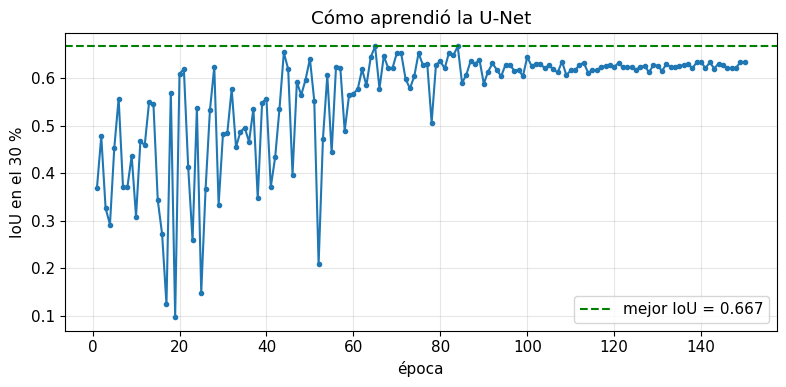

Mejor modelo guardado: /content/drive/MyDrive/PASO_A_PASO/RESULTADOS_UNET/unet_topa_rgb.pt


In [10]:
MODELO, HIST = entrenar_unet(X, M, S, MODELO, ENCODER="resnet34", EPOCAS=150, BATCH=6, LR=1e-4)

## <font color="greenyellow" size="6"><b>PASO 7 · Examen por píxel en el 30 %</b></font>
**Para qué:** medir qué tan bien marca los píxeles de topa en las teselas del 30 %.  
**Qué verás:** la tabla con IoU, Dice, precisión, recuperación, OA y Kappa (con su intervalo de confianza) y 3 ejemplos: tesela, topa real y lo que marcó la red.  
**Fuente:** evaluación por píxel de la segmentación: Maxwell et al. (2021). Intervalos sorteando teselas (1000 veces).

In [11]:
TAB = examen_unet(MODELO, X, M, S)
display(TAB)

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 8 · Detectar en todo el ortomosaico</b></font>
**Para qué:** correr el modelo en todo el ortomosaico y guardar sus copas de topa con su probabilidad.  
**Qué verás:** cuántas copas de topa encontró. Tarda varios minutos.  
**Fuente:** clase que da el modelo con umbral de decisión 0,50 (tutorial de Esri). Copa entera del watershed.

> Para usar el modelo de la tesis en vez del recién entrenado, antes de esta celda escribe: MODELO = "/content/drive/MyDrive/unet_topa_rgb.pt"

In [12]:
TOP, SHP_TOPA = detectar(MODELO, ORTO, SALIDA)

Corriendo el modelo en todo el ortomosaico (puede tardar varios minutos)…
Modelo unet_topa_rgb · tipo UNET · orto ortomosaico_TOPA · forma mascaras
Modelo: unet_topa_rgb (U-Net resnet34, 3 canales) · bandas [1, 2, 3] · tesela 640 px · receta: tabla RECETAS
orto a 1.84 cm: 12528×17318 px · la U-Net recorre 36 franjas…
   franja 5/36 · faltan ~1.5 min
   franja 10/36 · faltan ~1.2 min
   franja 15/36 · faltan ~0.9 min
   franja 20/36 · faltan ~0.7 min
   franja 25/36 · faltan ~0.5 min
   franja 30/36 · faltan ~0.3 min
   franja 35/36 · faltan ~0.0 min
   listo en 1.6 min
Forma «copa entera»: uso las 1419 copas de todo ortomosaico_TOPA ya hechas (/content/drive/MyDrive/COLAB/vuelo 1_ortocorregido/imagen_prueba/copas_entera_ortomosaico_TOPA_d3_a22-79.25.gpkg)
   342 topas del modelo → 342 con forma de copa entera del watershed: 2 con las copas que tienen más de la mitad dentro · 340 con la copa donde cae la mayor parte · 0 fuera de la segmentación (como las marcó el modelo) · 175 caen en l

## <font color="greenyellow" size="6"><b>PASO 9 · Mapa final (tú eliges el estilo)</b></font>
**Para qué:** dibujar el mapa de presentación. Cambia los valores para elegir el título, las letras, los colores, la leyenda y lo demás.  
**Qué verás:** el mapa con marco, coordenadas en los 4 lados, escala, norte y leyenda; queda guardado en SALIDA. Si solo cambias el estilo, corre esta celda otra vez (no hace falta detectar de nuevo).

> Colores: escríbelos con su nombre en español (verde, rojo, rojo vivo, amarillo, naranja, azul, celeste, morado, rosado, marrón, gris, negro, blanco…) o en inglés (green, red, black…); «ninguno» = sin relleno. Para ver todos los colores: ver_colores(). Lugar de la leyenda: «arriba derecha», «arriba izquierda», «abajo derecha», «abajo izquierda» o «centro». Transparencia: de 0 (invisible) a 1 (opaco).

In [13]:
TOP = gpd.read_file(f"{SALIDA}/topa_unet_topa_rgb_ortomosaico_TOPA_ws_esri.shp")   # tus copas ya detectadas
mapa_final(ORTO, TOP, "U-Net", SALIDA,
           titulo="Detección de", especie="Ochroma pyramidale", tam_titulo=13,
           relleno="rojo", transparencia=0.45, borde="amarillo", grosor=0.7,
           titulo_leyenda=None, tam_leyenda=9, pos_leyenda="abajo derecha",
           norte=True, tam_norte=0.6, pos_norte="arriba derecha", fondo_norte="blanco",
           escala=True, largo_escala=None, tramos_escala=4, tam_escala=1.0, pos_escala="abajo izquierda",
           coordenadas=True, tam_coord=8, cada_coord=None, lados_coord="cuatro", sistema=True,
           tam_letra=8, color_marco="negro", ancho=9, dpi=300)

Output hidden; open in https://colab.research.google.com to view.

## <font color="greenyellow" size="6"><b>PASO 10 · Ortomosaico interactivo con barra de umbral</b></font>
**Para qué:** mover y acercar el ortomosaico con el ratón y mover la barra de umbral: se ven las copas con probabilidad mayor que el umbral y cuántas son.  
**Qué verás:** la página interactiva. En 0,50 marca las mismas copas que el mapa final. Al pasar el ratón sobre una copa se ve su probabilidad; la otra barra aclara el ortomosaico.

> En la U-Net la barra usa la probabilidad media de cada copa marcada (cada píxel ya pasó 0,50).

In [ ]:
mapa_interactivo(ORTO, SHP_TOPA, umbral=0.50, titulo="Detección de Ochroma pyramidale",
                 relleno="rojo vivo", borde="blanco", transparencia=0.40, grosor=1.2, tam_letra=14, alto=650)

## <font color="greenyellow" size="6"><b>PASO 11 · Guardar las copas del umbral que elegiste</b></font>
**Para qué:** guardar en un SHP (para ArcGIS o QGIS) las copas con probabilidad mayor que el umbral que elegiste en la barra.  
**Qué verás:** cuántas copas pasaron el umbral y dónde quedó el SHP.

> Para el mapa de presentación con ese umbral: mapa_final(ORTO, TOP_U, "U-Net", SALIDA, titulo="Detección de", relleno="rojo")

In [ ]:
TOP_U, SHP_U = guardar_umbral(SHP_TOPA, umbral=0.50)      # pon aquí el umbral que elegiste en la barra